In [255]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import os, json

SEED = 42
TARGET = 'Stress_Level'
NUM = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity']
pd.set_option('display.max_columns', None)

# Modul A - Data understanding & EDA
## A.1 Memuat data


In [256]:
df_raw = pd.read_csv('Student lifestyle data.csv')
df = df_raw.copy()
print('Ukuran dataset:', df.shape)
df.sample(5)

Ukuran dataset: (100000, 10)


,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
25132,26133,24.0,Male,Medical,2.29,8.4,3.6,3.6,20.0,5.0
70858,71859,22.0,Male,Arts,3.08,6.9,7.1,4.4,65.0,4.0
80877,81878,21.0,Male,Science,2.31,8.8,4.3,3.2,138.0,5.0
33455,34456,20.0,Male,Science,3.05,7.2,3.5,3.8,20.0,6.0
89100,90101,23.0,Male,Engineering,3.00,5.7,7.0,3.0,122.0,3.0


In [257]:
df.describe()

,Student_ID,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
count,100000.000000,98000.000000,98000.000000,98000.000000,98000.000000,98000.000000,98000.000000,98000.000000
mean,51000.500000,21.009020,2.897737,6.994409,4.510430,3.503534,74.354439,4.131745
std,28867.657797,2.000311,0.532342,1.498520,1.976138,1.486421,43.363699,1.424681
min,1001.000000,18.000000,1.560000,3.000000,0.000000,0.000000,0.000000,2.000000
25%,26000.750000,19.000000,2.450000,6.000000,3.200000,2.500000,37.000000,3.000000
50%,51000.500000,21.000000,2.900000,7.000000,4.500000,3.500000,74.000000,4.000000
75%,76000.250000,23.000000,3.350000,8.000000,5.800000,4.500000,112.000000,5.000000
max,101000.000000,24.000000,4.000000,12.000000,12.800000,10.000000,149.000000,10.000000


In [258]:
df.info()
print('\nDuplikat:', df_raw.duplicated().sum())
df_raw.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Student_ID          100000 non-null  int64  
 1   Age                 98000 non-null   float64
 2   Gender              98000 non-null   object 
 3   Department          98000 non-null   object 
 4   CGPA                98000 non-null   float64
 5   Sleep_Duration      98000 non-null   float64
 6   Study_Hours         98000 non-null   float64
 7   Social_Media_Hours  98000 non-null   float64
 8   Physical_Activity   98000 non-null   float64
 9   Stress_Level        98000 non-null   float64
dtypes: float64(7), int64(1), object(2)
memory usage: 7.6+ MB

Duplikat: 0


,Student_ID,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
count,100000.00,98000.00,98000.00,98000.00,98000.00,98000.00,98000.00,98000.00
mean,51000.50,21.01,2.90,6.99,4.51,3.50,74.35,4.13
std,28867.66,2.00,0.53,1.50,1.98,1.49,43.36,1.42
min,1001.00,18.00,1.56,3.00,0.00,0.00,0.00,2.00
25%,26000.75,19.00,2.45,6.00,3.20,2.50,37.00,3.00
50%,51000.50,21.00,2.90,7.00,4.50,3.50,74.00,4.00
75%,76000.25,23.00,3.35,8.00,5.80,4.50,112.00,5.00
max,101000.00,24.00,4.00,12.00,12.80,10.00,149.00,10.00


## A.1 Missing value

In [259]:
print(df_raw.isna().sum())
print('\nBaris dengan minimal 1 nilai kosong:', df_raw.isna().any(axis=1).sum())

Student_ID               0
Age                   2000
Gender                2000
Department            2000
CGPA                  2000
Sleep_Duration        2000
Study_Hours           2000
Social_Media_Hours    2000
Physical_Activity     2000
Stress_Level          2000
dtype: int64

Baris dengan minimal 1 nilai kosong: 16631


- Setiap kolom kosong itu sekitar **2%**, tersebar di **16,6% baris**. Kalau semua baris tidak lengkap dibuang, terlalu banyak data yang hilang.
- **Label kosong → dibuang** (2.000 baris), karena tidak bisa dipakai belajar.
- **Fitur kosong → diisi median/modus di Modul B**, memakai nilai dari data latih saja supaya tidak bocor.
- Tidak ada duplikat, dan semua nilai masuk rentang wajar.

In [260]:
df = df_raw.drop(columns='Student_ID').dropna(subset=[TARGET]).reset_index(drop=True)
df.to_csv('df_clean.csv', index=False)
df.shape

(98000, 9)

## A.2 EDA

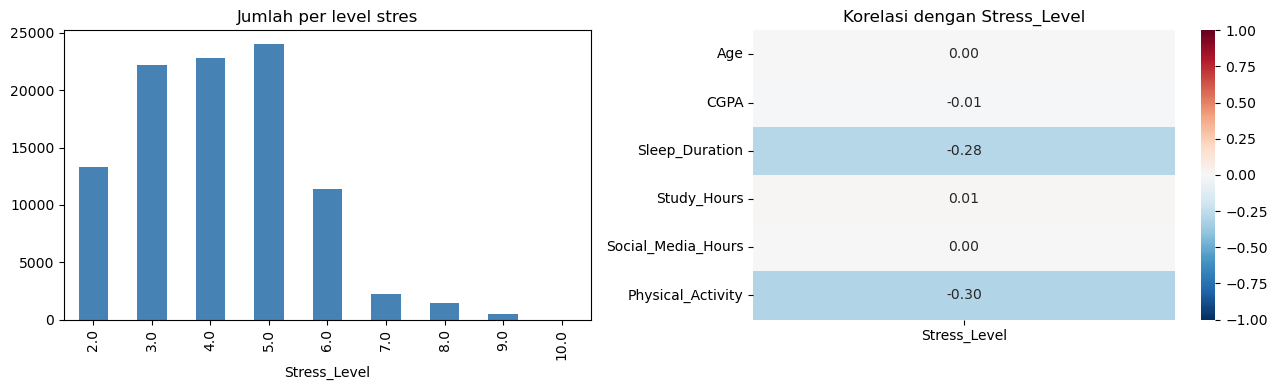

In [261]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue', title='Jumlah per level stres')
sns.heatmap(df[NUM + [TARGET]].corr()[[TARGET]].drop(TARGET), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Korelasi dengan Stress_Level')
plt.tight_layout(); plt.show()

Stres terbanyak di level 3-5. hanya **Sleep_Duration (-0.28)** dan **Physical_activity (-0.30)** yang berkolerasi dengan stres. Fitur lain hampir 0.

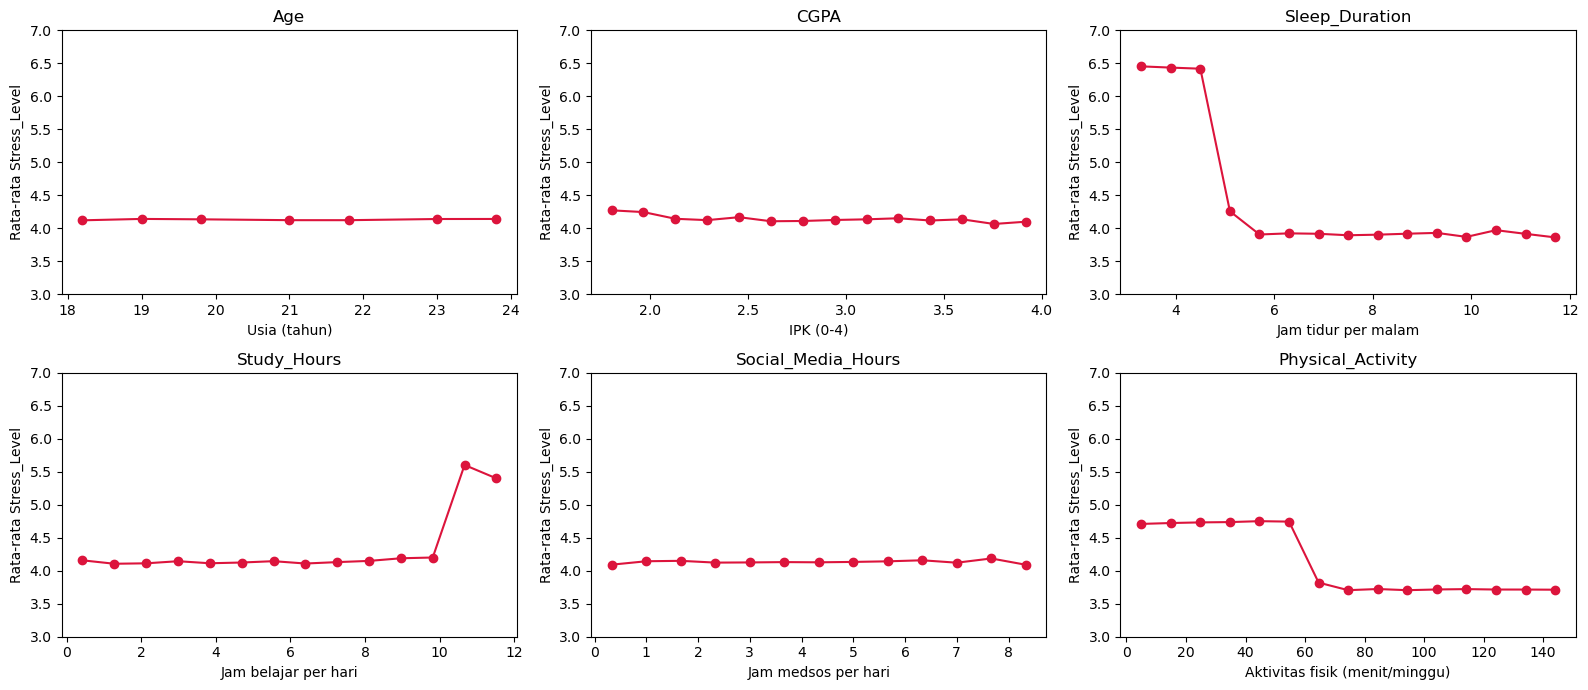

{'Female': 4.13, 'Male': 4.13}
{'Arts': 4.13, 'Business': 4.13, 'Engineering': 4.13, 'Medical': 4.12, 'Science': 4.15}


In [262]:
# Rata-rata stres per kelompok nilai: melihat BENTUK hubungannya
SATUAN = {'Age': 'Usia (tahun)', 'CGPA': 'IPK (0-4)', 'Sleep_Duration': 'Jam tidur per malam',
          'Study_Hours': 'Jam belajar per hari', 'Social_Media_Hours': 'Jam medsos per hari',
          'Physical_Activity': 'Aktivitas fisik (menit/minggu)'}

fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for a, c in zip(ax.ravel(), NUM):
    g = df.groupby(pd.cut(df[c], 15), observed=True)[TARGET].agg(['mean', 'count'])
    g = g[g['count'] >= 30]
    a.plot([i.mid for i in g.index], g['mean'], marker='o', color='crimson')
    a.set_title(c); a.set_ylim(3, 7)
    a.set_xlabel(SATUAN[c])                    # sumbu x: nilai fitur
    a.set_ylabel('Rata-rata Stress_Level')     # sumbu y: rata-rata stres kelompok itu
    a.set
plt.tight_layout(); plt.show()

print(df.groupby('Gender')[TARGET].mean().round(2).to_dict())
print(df.groupby('Department')[TARGET].mean().round(2).to_dict())

**Hubungannya berbentuk tangga, bukan garis miring:**
- Tidur **di bawah 5 jam** → stres melonjak.
- Aktivitas fisik **60 menit ke bawah** → stres naik.
- Belajar **lebih dari 10 jam** → stres naik.
- Usia, IPK, medsos, gender, jurusan: **datar**, tidak berpengaruh.

In [263]:
for c, lo, hi in [('Sleep_Duration', 4.7, 5.2), ('Physical_Activity', 58, 63), ('Study_Hours', 9.8, 10.3)]:
    s = df[df[c].between(lo, hi)]
    print(c, s.groupby(s[c].round(1))[TARGET].mean().round(2).to_dict())

Sleep_Duration {4.7: 6.36, 4.8: 6.46, 4.9: 6.41, 5.0: 3.98, 5.1: 3.97, 5.2: 3.87}
Physical_Activity {58.0: 4.73, 59.0: 4.73, 60.0: 4.71, 61.0: 3.76, 62.0: 3.71, 63.0: 3.72}
Study_Hours {9.8: 3.98, 9.9: 4.45, 10.0: 4.0, 10.1: 5.66, 10.2: 5.71, 10.3: 6.11}


**Kesimpulan EDA:** titik lompatannya tepat di **tidur 5 jam**, **aktivitas 60 menit**, dan **belajar 10 jam**. Ketiga batas ini dijadikan **fitur 0/1** di Modul B.

# MODUL B — Pemodelan Linear Regression
## B.1 Split 70 / 15 / 15
Latih 70% (belajar), validasi 15% (memilih model dan batas kategori), uji 15% (nilai akhir, dibuka sekali). Stratified per level stres.

In [264]:

def stratified_split(y, fracs=(0.70, 0.15, 0.15), seed=SEED):
    rng = np.random.default_rng(seed)
    parts = [[] for _ in fracs]

    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])

        cuts = np.round(
            np.cumsum(fracs)[:-1] * len(idx)
        ).astype(int)

        for i, potong in enumerate(np.split(idx, cuts)):
            parts[i].extend(potong)

    return [np.sort(p) for p in parts]


idx_tr, idx_va, idx_te = stratified_split(df[TARGET].values)

train, val, test = ( df.iloc[idx_tr].copy(), df.iloc[idx_va].copy(), df.iloc[idx_te].copy())

y_tr = train[TARGET].values
y_va = val[TARGET].values
y_te = test[TARGET].values

bagian = {
    'semua': df,
    'latih (70%)': train,
    'validasi (15%)': val,
    'uji (15%)': test
}

print(pd.DataFrame({
    'jumlah data': [len(d) for d in bagian.values()],
    'jumlah stres >= 7.0': [
        (d[TARGET] >= 7.0).sum() for d in bagian.values()
    ],
    '% stres >= 7.0': [
        round((d[TARGET] >= 7.0).mean() * 100, 2)
        for d in bagian.values()
    ]
}, index=bagian.keys()))

                jumlah data  jumlah stres >= 7.0  % stres >= 7.0
semua                 98000                 4159            4.24
latih (70%)           68601                 2911            4.24
validasi (15%)        14699                  624            4.25
uji (15%)             14700                  624            4.24


## B.2 Preprocessing dan rumus

**Preprocessing** (semua dihitung dari data latih):
- Isi kosong: **median** (angka), **modus** (kategori).
- **Fitur ambang** (hasil EDA), nilainya 0/1: `Tidur_Kurang` (tidur < 5), `Aktivitas_Rendah` (aktivitas ≤ 60), `Belajar_Berlebih` (belajar > 10).
- Untuk versi pembanding (fitur asli): one-hot Gender & Department.
- **Z-score** semua fitur, supaya satu learning rate cocok untuk semua fitur.

**Linear Regression:**
1. Prediksi: **ŷ = X·w + b**
2. Loss MSE: **(1/n) Σ (ŷ − y)²**
3. Gradien: **∂/∂w = (2/n) Xᵀ(ŷ − y)**, **∂/∂b = (2/n) Σ(ŷ − y)**
4. Update: **w ← w − lr · gradien**, diulang sebanyak `epochs`.

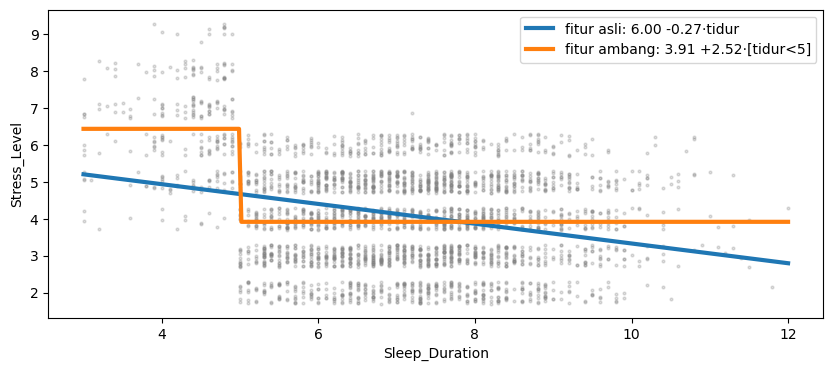

In [265]:
s = train[['Sleep_Duration', TARGET]].dropna()
x, y = s['Sleep_Duration'].values, s[TARGET].values
b1, w1 = np.polyfit(x, y, 1)[::-1]
b2, w2 = np.polyfit((x < 5).astype(float), y, 1)[::-1]

grid = np.linspace(3, 12, 300)
idx = np.random.default_rng(SEED).choice(len(x), 3000, replace=False)
plt.figure(figsize=(10, 4))
plt.scatter(x[idx], y[idx] + np.random.default_rng(1).uniform(-0.3, 0.3, 3000), s=4, alpha=0.25, color='gray')
plt.plot(grid, b1 + w1 * grid, lw=3, label=f'fitur asli: {b1:.2f} {w1:+.2f}·tidur')
plt.plot(grid, b2 + w2 * (grid < 5), lw=3, label=f'fitur ambang: {b2:.2f} {w2:+.2f}·[tidur<5]')
plt.xlabel('Sleep_Duration'); plt.ylabel(TARGET); plt.legend(); plt.show()

## B.3 Class model

In [266]:
%%writefile model_linreg.py

import json
import numpy as np
import pandas as pd

class Preprocessor:
    NUM = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity']
    KAT = ['Gender', 'Department']

    def __init__(self, ambang=True):
        self.ambang = ambang

    def fit(self, data):
        """Pelajari semua parameter dari data LATIH."""
        self.median = {c: float(data[c].median()) for c in self.NUM}
        self.modus = {c: str(data[c].mode()[0]) for c in self.KAT}
        self.onehot = {c: sorted(str(k) for k in data[c].dropna().unique() if k != self.modus[c]) for c in self.KAT}
        X = self.fitur_mentah(data)
        self.kolom = list(X.columns)
        self.mean = X.mean().to_dict()
        self.std = X.std().to_dict()
        return self

    def fitur_mentah(self, data):
        """Isi kosong lalu buat fitur (belum di-z-score). data bisa DataFrame atau dict (dari GUI)."""
        if isinstance(data, dict):
            data = pd.DataFrame([data])
        d = data.copy()
        for c in self.NUM:
            d[c] = pd.to_numeric(d[c], errors='coerce').fillna(self.median[c])
        for c in self.KAT:
            d[c] = d[c].fillna(self.modus[c])
        X = pd.DataFrame(index=d.index)
        if self.ambang:
            X['Tidur_Kurang'] = d['Sleep_Duration'] < 5
            X['Aktivitas_Rendah'] = d['Physical_Activity'] <= 60
            X['Belajar_Berlebih'] = d['Study_Hours'] > 10
        else:
            for c in self.NUM:
                X[c] = d[c]
            for c, kelas in self.onehot.items():
                for k in kelas:
                    X[f'{c}_{k}'] = d[c] == k
        return X.astype(float)

    def transform(self, data):
        """Fitur + z-score memakai mean/std data latih."""
        X = self.fitur_mentah(data)[self.kolom]
        return (X - pd.Series(self.mean)) / pd.Series(self.std)

class LinearRegression:
    def __init__(self, lr=0.1, epochs=500):
        self.lr, self.epochs = lr, epochs

    def predict(self, X):
        return X @ self.w + self.b

    def loss(self, X, y): 
        return np.mean((self.predict(X) - y) ** 2)

    def fit(self, X, y):
        """Gradiant Descent"""
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.riwayat = []
        for _ in range(self.epochs):
            self.riwayat.append(self.loss(X, y))
            err = self.predict(X) - y
            self.w -= self.lr * 2 * X.T @ err / len(y)
            self.b -= self.lr * 2 * err.mean()
        return self

class StressModel:
    KATEGORI = np.array(['Rendah', 'Sedang', 'Tinggi'])

    def __init__(self, prep, model, batas=(3.5, 5.5)): # CATATAN Batas masih ditentukan secara manual / belum tentu ini batas terbaik
        self.prep, self.model, self.batas = prep, model, list(batas)

    @staticmethod
    def ke_kategori(nilai, batas=(3.5, 5.5)): # CATATAN Batas masih ditentukan secara manual / belum tentu ini batas terbaik
        return StressModel.KATEGORI[np.digitize(nilai, batas)]

    def skor(self, data):
        """Prediksi level stres 0-10."""
        return np.clip(self.model.predict(self.prep.transform(data).values), 0, 10)

    def prediksi(self, data):
        s = self.skor(data)
        return s, self.ke_kategori(s, self.batas)

    def koefisien(self):
        """Bobot dalam satuan asli: efek = w / std, intercept = b - sum(efek * mean)."""
        efek = pd.Series(self.model.w, index=self.prep.kolom) / pd.Series(self.prep.std)[self.prep.kolom]
        intercept = self.model.b - (efek * pd.Series(self.prep.mean)[self.prep.kolom]).sum()
        return float(intercept), efek

    def save(self, path):
        p = self.prep
        isi = {'ambang': p.ambang, 'median': p.median, 'modus': p.modus, 'onehot': p.onehot, 'kolom': p.kolom,
               'mean': p.mean, 'std': p.std, 'w': self.model.w.tolist(), 'b': float(self.model.b), 'batas': self.batas}
        with open(path, 'w') as f:
            json.dump(isi, f, indent=1)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            isi = json.load(f)
        prep = Preprocessor(isi['ambang'])
        for k in ['median', 'modus', 'onehot', 'kolom', 'mean', 'std']:
            setattr(prep, k, isi[k])
        model = LinearRegression()
        model.w, model.b = np.array(isi['w']), isi['b']
        return cls(prep, model, isi['batas'])

Overwriting model_linreg.py


In [267]:
%run model_linreg.py

## B.4 Training Model

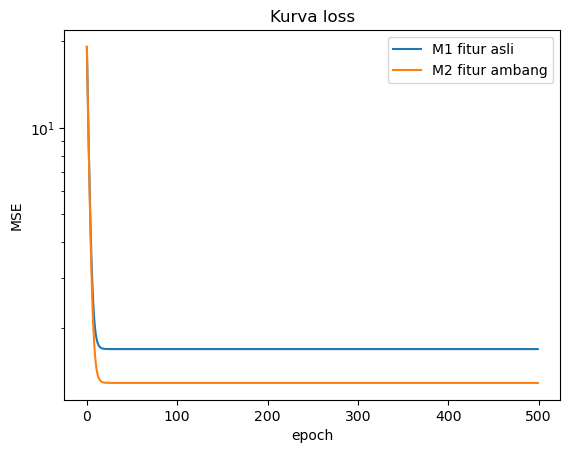

In [268]:
hasil = {}
for nama, ambang in [('M1 fitur asli', False), ('M2 fitur ambang', True)]:
    prep = Preprocessor(ambang=ambang).fit(train)
    model = LinearRegression(lr=0.1, epochs=500).fit(prep.transform(train).values, y_tr)
    hasil[nama] = StressModel(prep, model)
    plt.plot(model.riwayat, label=nama)
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.title('Kurva loss'); plt.show()

## B.5 Pilih model dengan data validasi

Metrik yang digunakan:

    R²: mengukur seberapa baik model menjelaskan variasi nilai target.

    MAE: rata-rata selisih absolut antara nilai aktual dan prediksi.

    RMSE: mengukur besar kesalahan dengan penalti lebih besar untuk kesalahan yang besar.

In [279]:
def metrik(y, p):
    return {'R2': 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2),
            'MAE': np.mean(np.abs(y - p)),
            'RMSE': np.sqrt(np.mean((y - p) ** 2))}

pd.DataFrame({nama: metrik(y_va, sm.skor(val)) for nama, sm in hasil.items()}).T.round(3)

,R2,MAE,RMSE
M1 fitur asli,0.166,1.090,1.301
M2 fitur ambang,0.362,1.007,1.138


stres = 3.51 +2.51·[Tidur_Kurang] +1.00·[Aktivitas_Rendah] +1.35·[Belajar_Berlebih]


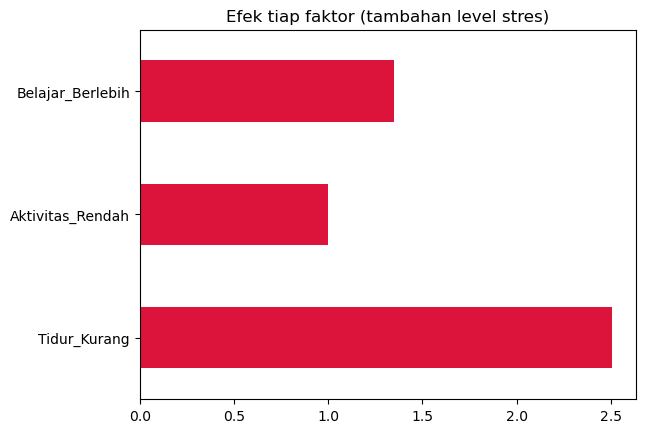

In [270]:
stress_model = hasil['M2 fitur ambang']
intercept, efek = stress_model.koefisien()
print(f'stres = {intercept:.2f} ' + ' '.join(f'{v:+.2f}·[{k}]' for k, v in efek.items()))
efek.plot.barh(color='crimson', title='Efek tiap faktor (tambahan level stres)'); plt.show()

- Fitur ambang membuat **R² naik dari 0,17 ke 0,36**. Jadi **M2 dipilih**.
- Gradient descent memberi hasil **sama** dengan Normal Equation (selisih 10⁻¹⁵). Artinya training sudah benar.
- **Cara membaca rumus:** stres dasar 3,5. **Kurang tidur +2,5** (faktor terkuat), belajar berlebih +1,35, aktivitas rendah +1.

## B.6 Pilih batas kategori terbaik - Hyperparameter Tuning

In [280]:
LABEL = list(StressModel.KATEGORI)

pred_va = stress_model.skor(val)
kat_va = StressModel.ke_kategori(y_va)


def macro_f1(asli, pred):
    f1 = []
    for k in LABEL:
        tp = np.sum((asli == k) & (pred == k))
        p, r = tp / max(np.sum(pred == k), 1), tp / np.sum(asli == k)
        f1.append(2 * p * r / (p + r) if p + r else 0)
    return np.mean(f1)

kandidat = [(a, b) for a in np.arange(1.0, 5.0, 0.25) for b in np.arange(a + 0.5, 10.0, 0.25)]
skor_batas = {k: macro_f1(kat_va, StressModel.ke_kategori(pred_va, k)) for k in kandidat}
terbaik = max(skor_batas, key=skor_batas.get)
stress_model.batas = [float(terbaik[0]), float(terbaik[1])]
print(f'Batas 3,5 & 5,5 -> macro F1 validasi {skor_batas[(3.5, 5.5)]:.3f}')
print(f'Batas terbaik {stress_model.batas} -> macro F1 validasi {skor_batas[terbaik]:.3f}')

Batas 3,5 & 5,5 -> macro F1 validasi 0.390
Batas terbaik [3.75, 4.75] -> macro F1 validasi 0.516


Macro F1 disini maksudnya adalah F1 rata-rata dari semua Kategori target (Disini kategorinya 3 'Rendah', 'Sedang', dan 'Tinggi')

Hasil batas terbaik ternyata adalah 3.75 dan 4.75

Action yang diambil adalah mengubah threshold model menjadi 3.75 dan 4.75

In [272]:
stress_model.save('model_stres_lr.json')
print('Model tersimpan, batas:', stress_model.batas)

Model tersimpan, batas: [3.75, 4.75]


# Modul C

## C.1 Confusion Matrix

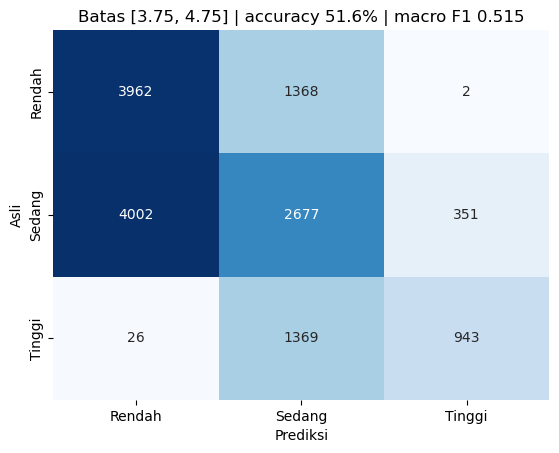

        precision  recall     f1
Rendah      0.496   0.743  0.595
Sedang      0.494   0.381  0.430
Tinggi      0.728   0.403  0.519


In [273]:
pred_te = stress_model.skor(test)
LABEL = list(StressModel.KATEGORI)
kat_asli = StressModel.ke_kategori(y_te)

def confusion_matrix(asli, pred):
    cm = pd.DataFrame(0, index=LABEL, columns=LABEL)
    for a in LABEL:
        for p in LABEL:
            cm.loc[a, p] = np.sum((asli == a) & (pred == p))
    return cm

def evaluasi_kategori(asli, pred, judul):
    cm = confusion_matrix(asli, pred)
    tp = np.diag(cm.values)
    precision = tp / np.maximum(cm.sum(axis=0).values, 1)
    recall = tp / cm.sum(axis=1).values
    f1 = np.where(precision + recall > 0, 2 * precision * recall / np.maximum(precision + recall, 1e-12), 0)
    acc = tp.sum() / cm.values.sum()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'{judul} | accuracy {acc:.1%} | macro F1 {f1.mean():.3f}'); plt.ylabel('Asli'); plt.xlabel('Prediksi'); plt.show()
    print(pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1}, index=LABEL).round(3))
    return f1.mean()

f1 = evaluasi_kategori(kat_asli, StressModel.ke_kategori(pred_te, stress_model.batas), f'Batas {stress_model.batas}')

## C.2 Permasasalahan terkait akurasi

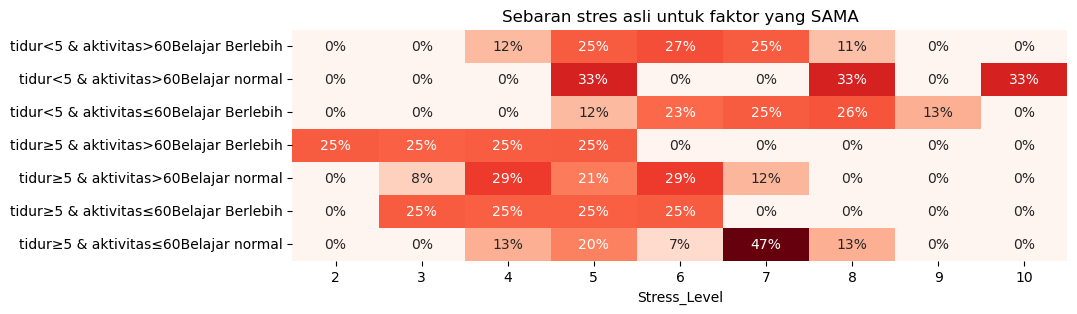

In [284]:
f = stress_model.prep.fitur_mentah(test)
kelompok = [
    f"{'tidur<5' if t == 1 else 'tidur≥5'} & "
    f"{'aktivitas≤60' if a == 1 else 'aktivitas>60'}"
    f"{'Belajar normal' if z == 1 else 'Belajar Berlebih'}"
    for t, a, z in zip(f['Tidur_Kurang'], f['Aktivitas_Rendah'], f['Belajar_Berlebih'])
]
plt.figure(figsize=(10, 3))
sns.heatmap(pd.crosstab(kelompok, y_te.astype(int), normalize='index'), annot=True, fmt='.0%', cmap='Reds', cbar=False)
plt.title('Sebaran stres asli untuk faktor yang SAMA'); plt.xlabel(TARGET); plt.ylabel(''); plt.show()

Mahasiswa **tanpa faktor risiko** punya stres 2, 3, 4, atau 5 dengan peluang **sama (25% masing-masing)**. Input sama, jawaban acak. Jadi model apa pun **tidak bisa** menebak lebih tepat. Accuracy ±52% ini sudah **batas maksimum** data ini, bukan karena modelnya lemah.

## C.3 Evaluasi Regresi pada Test Set

Pada bagian ini, model final dievaluasi menggunakan test set yang tidak digunakan untuk training maupun pemilihan threshold.

Metrik yang digunakan:

    R²: mengukur seberapa baik model menjelaskan variasi nilai target.

    MAE: rata-rata selisih absolut antara nilai aktual dan prediksi.

    RMSE: mengukur besar kesalahan dengan penalti lebih besar untuk kesalahan yang besar.

Hasil test set digunakan sebagai estimasi performa akhir, bukan untuk memilih ulang model atau threshold.

In [275]:
pred_te = stress_model.skor(test)

hasil_test = pd.DataFrame({
    'Baseline (rata-rata)': metrik(
        y_te,
        np.full(len(y_te), y_tr.mean())
    ),
    'Model final': metrik(y_te, pred_te)
}).T

display(hasil_test.round(3))


,R2,MAE,RMSE
Baseline (rata-rata),-0.000,1.154,1.425
Model final,0.364,1.006,1.136


## C.4 Analisis kesalahan model

In [276]:

kat_pred = StressModel.ke_kategori(pred_te, stress_model.batas)

analisis_error = test[
    ['Age', 'CGPA', 'Sleep_Duration',
     'Study_Hours', 'Physical_Activity', TARGET]
].copy()

analisis_error['Prediksi_Stres'] = pred_te
analisis_error['Kategori_Asli'] = kat_asli
analisis_error['Kategori_Prediksi'] = kat_pred
analisis_error['Benar'] = kat_asli == kat_pred

display(
    analisis_error.loc[~analisis_error['Benar']]
    .sample(10)
    .round(2)
)


,Age,CGPA,Sleep_Duration,Study_Hours,Physical_Activity,Stress_Level,Prediksi_Stres,Kategori_Asli,Kategori_Prediksi,Benar
37136,22.0,2.00,6.7,1.6,111.0,5.0,3.51,Sedang,Rendah,False
97563,NaN,2.71,4.7,2.9,62.0,4.0,6.02,Sedang,Tinggi,False
73779,22.0,3.19,7.1,4.2,39.0,3.0,4.52,Rendah,Sedang,False
63022,24.0,3.49,6.1,3.0,0.0,6.0,4.52,Tinggi,Sedang,False
92701,20.0,2.32,8.0,4.0,6.0,3.0,4.52,Rendah,Sedang,False
63517,18.0,2.70,8.8,1.9,136.0,4.0,3.51,Sedang,Rendah,False
92943,21.0,2.09,8.8,NaN,38.0,3.0,4.52,Rendah,Sedang,False
64368,24.0,3.30,6.2,6.4,37.0,3.0,4.52,Rendah,Sedang,False
34627,24.0,3.88,7.2,7.3,55.0,3.0,4.52,Rendah,Sedang,False
59261,20.0,2.11,8.2,2.0,78.0,5.0,3.51,Sedang,Rendah,False


## C.5 Save model

In [277]:
stress_model.save('model_stres_lr.json')